# Projet RTLS RFID UHF — Notebook de rendu

L'objectif est d'estimer la position d'un tag RFID dans l'espace, notée :
$$
\mathbf{r}=(x,y,z)
$$
à partir des mesures RSSI obtenues par **4 antennes** et **3 puissances d'émission** (\(24, 27, 30\) dBm).

Le sujet propose plusieurs axes d'amélioration. Nous les explorons explicitement :

1. **Améliorer les features** (au-delà du simple RSSImax).
2. **Comparer des cibles** : prédire \((x,y,z)\) directement, prédire des distances (D_1..D_4\), et prédire \((x,y,z,D_1..D_4)\) ensemble.
3. **Stratégies multi-puissance** : entraîner un modèle par puissance puis fusionner (late fusion).
4. **“Gros bouton”** suggéré : restreindre l'étude au carré des antennes (2×2 m) et comparer à l'extérieur.
5. **Analyse d'erreurs détaillée** : par zone, par hauteur \(z\), par nombre de lectures (RCNT), et **heatmap** spatiale.
6. **Approche RTLS engineering** : calibration simple par puissance, modèle physique RSSI→distance (log-distance), et gestion du cas coplanaire (z instable).

Le but n'est pas de “tester au hasard”, mais de construire une démarche structurée :  
**baseline → améliorations → validation robuste → comparaison de variantes → analyse et interprétation**.

## 1) Environnement, chemins et reproductibilité


In [ ]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

from google.colab import drive
drive.mount("/content/drive")

DATA_ROOT = "/content/drive/MyDrive/drive-download-20260218T142550Z-1-001"

CONF_DIR = os.path.join(DATA_ROOT, "Conf=2025-12-19__site=ismin__antConf=square2m")
ACT_DIR  = os.path.join(DATA_ROOT, "Actuals_ismin")

assert os.path.isdir(CONF_DIR), f"Dossier introuvable: {CONF_DIR}"
assert os.path.isdir(ACT_DIR),  f"Dossier introuvable: {ACT_DIR}"

print("CONF_DIR =", CONF_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CONF_DIR = /content/drive/MyDrive/drive-download-20260218T142550Z-1-001/Conf=2025-12-19__site=ismin__antConf=square2m


## 2) Vérité terrain : association EPC → hauteur z

Le protocole de la campagne place 75 tags sur un mât, répartis sur 3 hauteurs :
$z$ $ϵ$ {0.5, 1.5, 2.5} m.


Les EPC correspondants à chaque hauteur sont donnés dans trois fichiers CSV.
On reconstruit donc une table `actuals` qui associe chaque EPC à sa valeur de \(z\).

**Pourquoi c'est important :** sans cette table, on n'aurait pas la vérité terrain complète \((x,y,z)\),
et on ne pourrait pas entraîner un modèle supervisé.

In [ ]:
def load_actuals(actuals_dir: str) -> pd.DataFrame:
    # Construit une table EPC -> z à partir des fichiers z=0.5.csv, z=1.5.csv, z=2.5.csv
    dfs = []
    for fn in os.listdir(actuals_dir):
        m = re.search(r"z=([0-9.]+)\.csv$", fn)
        if not m:
            continue
        z = float(m.group(1))
        df = pd.read_csv(os.path.join(actuals_dir, fn), sep=";", header=None, names=["EPC"], dtype=str)
        df["z"] = z
        dfs.append(df)

    actuals = pd.concat(dfs, ignore_index=True).dropna()
    actuals["EPC"] = actuals["EPC"].astype(str)
    return actuals

actuals = load_actuals(ACT_DIR)
print("EPC uniques :", actuals["EPC"].nunique())
print("Répartition par z :")
print(actuals["z"].value_counts().sort_index())
display(actuals.head())

EPC uniques : 75
Répartition par z :
z
0.5    25
1.5    25
2.5    25
Name: count, dtype: int64


,EPC,z
0,00000010000001745039910E,0.5
1,0000001000000174503963EE,0.5
2,0000001000000174503973AD,0.5
3,0000001000000174504035CE,0.5
4,000000100000017450396804,0.5


## 3) Parsing robuste des fichiers de mesures (CSV “reader”)

Chaque fichier de mesures correspond à une position \((x,y)\) de la grille.

- Les noms de fichiers contiennent la position, par exemple :  
  `x=-2__y=0__site=ismin_...csv`
- La puissance d'émission est dans les métadonnées (`PowerInDbm=...`).
- Les données (lectures RFID) sont séparées par `;` et commencent après des lignes `//`.

On reconstruit une table `raw` où **chaque ligne correspond à une lecture** :
$$
(\text{Timestamp}, \text{EPC}, \text{Antenna}, RSSI, x, y, power).
$$


In [ ]:
def extract_xy_from_filename(filename: str) -> tuple[float, float]:
    # Extrait (x,y) du nom de fichier
    m = re.search(r"x=([-0-9]+)__y=([-0-9]+)", filename)
    if not m:
        raise ValueError(f"Nom de fichier inattendu: {filename}")
    return float(m.group(1)), float(m.group(2))

def extract_power_from_file(filepath: str) -> int | None:
    # Extrait PowerInDbm depuis les métadonnées (lignes commençant par //)
    power = None
    with open(filepath, "r") as f:
        for line in f:
            if line.startswith("// ReaderName"):
                mp = re.search(r"PowerInDbm=([0-9]+)", line)
                if mp:
                    power = int(mp.group(1))
            if not line.startswith("//"):
                break
    return power

def read_reader_csv(filepath: str) -> pd.DataFrame:
    # Lit un fichier reader : entête non standard + séparateur ';'
    with open(filepath, "r") as f:
        lines = f.readlines()
    if len(lines) < 4:
        return pd.DataFrame()

    header_line = lines[2].replace("// ", "").strip()
    cols = [c.strip() for c in header_line.split(",")]

    df = pd.read_csv(filepath, sep=";", skiprows=3, header=None, dtype=str)
    df.columns = cols

    needed = ["Timestamp", "EPC", "Antenna", "RSSI"]
    for c in needed:
        if c not in df.columns:
            return pd.DataFrame()

    df = df[needed].dropna(subset=["EPC","Antenna","RSSI"])

    # RSSI est parfois écrit avec virgule -> on normalise
    df["RSSI"] = df["RSSI"].astype(str).str.replace(",", ".", regex=False)
    df["RSSI"] = pd.to_numeric(df["RSSI"], errors="coerce")

    # Antenna en entier
    df["Antenna"] = pd.to_numeric(df["Antenna"], errors="coerce")
    df = df.dropna(subset=["RSSI","Antenna"])
    df["Antenna"] = df["Antenna"].astype(int)
    df["EPC"] = df["EPC"].astype(str)
    return df

def build_raw(conf_dir: str, actuals: pd.DataFrame) -> pd.DataFrame:
    # Concatène toutes les lectures de tous les fichiers de la configuration
    files = [f for f in os.listdir(conf_dir) if f.startswith("x=") and f.endswith(".csv")]
    recs = []

    for fn in files:
        fp = os.path.join(conf_dir, fn)
        x, y = extract_xy_from_filename(fn)
        power = extract_power_from_file(fp)

        df = read_reader_csv(fp)
        if df.empty:
            continue

        df["x"] = x
        df["y"] = y
        df["power"] = power
        df["run"] = fn
        recs.append(df)

    raw = pd.concat(recs, ignore_index=True)

    # Ajout de z via la vérité terrain (EPC -> z)
    raw = raw.merge(actuals, on="EPC", how="left").dropna(subset=["z"])
    return raw

raw = build_raw(CONF_DIR, actuals)
print("raw shape :", raw.shape)
print("Powers :", raw["power"].value_counts().sort_index().to_dict())
print("Antennas :", raw["Antenna"].value_counts().sort_index().to_dict())
display(raw.head())

raw shape : (323080, 9)
Powers : {24: 93112, 27: 112040, 30: 117928}
Antennas : {1: 97592, 2: 82544, 3: 68924, 4: 74020}


,Timestamp,EPC,Antenna,RSSI,x,y,power,run,z
0,2025-12-19T14:45:08.1329240+01:00,0000001000000174504034FF,1,-73.5,-2.0,-1.0,27,x=-2__y=-1__site=ismin_2025-12-19_14-45-08.csv,0.5
1,2025-12-19T14:45:08.1329240+01:00,0000001000000174504034FF,1,-73.5,-2.0,-1.0,27,x=-2__y=-1__site=ismin_2025-12-19_14-45-08.csv,0.5
2,2025-12-19T14:45:08.1329240+01:00,0000001000000174504034FF,1,-73.5,-2.0,-1.0,27,x=-2__y=-1__site=ismin_2025-12-19_14-45-08.csv,0.5
3,2025-12-19T14:45:08.1329240+01:00,0000001000000174504034FF,1,-73.5,-2.0,-1.0,27,x=-2__y=-1__site=ismin_2025-12-19_14-45-08.csv,0.5
4,2025-12-19T14:45:08.1380640+01:00,000000100000017450387359,1,-72.0,-2.0,-1.0,27,x=-2__y=-1__site=ismin_2025-12-19_14-45-08.csv,2.5


## 3bis) Contrôle qualité des données (taux de détection, distributions RSSI, censure)

Avant de modéliser, on vérifie rapidement la **qualité des mesures**.  
Sur ce type de RTLS RSSI, la performance est fortement liée à :

- la **censure** (valeurs manquantes remplacées par \(-120\) dBm) : elle reflète des non-détections,
- la **densité de lectures** : si un tag est rarement lu, l'agrégation est moins stable,
- des **différences systématiques** entre antennes / puissances (offsets, zones d'ombre).

Ces contrôles ne “donnent pas un meilleur score” directement, mais ils permettent :
1) de comprendre les limites physiques du système,  
2) de justifier les choix (features RCNT, calibration, fusion, etc.).

,power,Antenna,detection_rate
0,24,1,1.0
1,24,2,1.0
2,24,3,1.0
3,24,4,1.0
4,27,1,1.0
5,27,2,1.0
6,27,3,1.0
7,27,4,1.0
8,30,1,1.0
9,30,2,1.0


,power,Antenna,count,mean,std,min,median,max
0,24,1,27892,-67.076079,5.794787,-78.0,-68.0,-39.5
1,24,2,24280,-67.426277,5.776074,-77.5,-68.5,-40.5
2,24,3,16936,-68.030940,6.107480,-77.5,-70.0,-41.0
3,24,4,24004,-66.533328,5.723872,-77.0,-67.5,-40.5
4,27,1,34368,-68.269495,6.354241,-82.0,-69.5,-38.0
5,27,2,27148,-69.216222,6.059368,-81.5,-70.5,-37.0
6,27,3,26688,-69.718900,6.115555,-80.0,-71.0,-41.5
7,27,4,23836,-68.724367,6.039393,-81.5,-69.5,-37.0
8,30,1,35332,-68.496321,7.149480,-81.5,-69.5,-32.5
9,30,2,31116,-69.464648,6.623487,-82.0,-70.0,-30.5


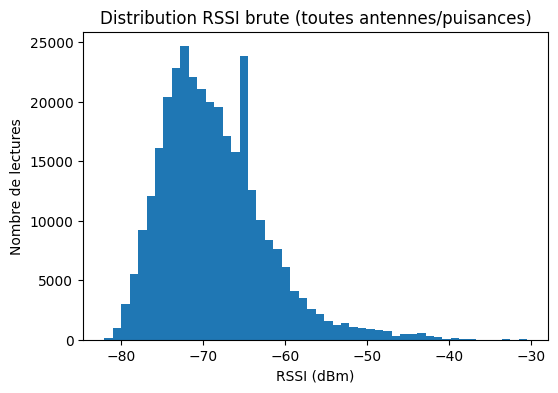

In [ ]:
# --- taux de détection (raw)
raw["is_detected"] = raw["RSSI"].notna().astype(int)

det_by_pa = (
    raw.groupby(["power","Antenna"])["is_detected"]
       .mean()
       .reset_index(name="detection_rate")
       .sort_values(["power","Antenna"])
)
display(det_by_pa)

# --- distribution RSSI brute par antenne et puissance (résumé)
rssi_summary = (
    raw.groupby(["power","Antenna"])["RSSI"]
       .agg(["count","mean","std","min","median","max"])
       .reset_index()
       .sort_values(["power","Antenna"])
)
display(rssi_summary)

# --- visualisation simple (histogramme RSSI global)
plt.figure(figsize=(6,4))
plt.hist(raw["RSSI"].dropna().to_numpy(float), bins=50)
plt.title("Distribution RSSI brute (toutes antennes/puisances)")
plt.xlabel("RSSI (dBm)")
plt.ylabel("Nombre de lectures")
plt.show()

## 4) Construction du dataset supervisé (agrégation des lectures)

Le modèle ne doit pas apprendre sur des lectures isolées, mais sur des **échantillons** correspondant à une position vraie.

On définit un échantillon supervisé comme :
$$
(\text{EPC}, x, y, z)
$$
et on construit des features en agrégeant toutes les lectures disponibles sur la fenêtre de mesure.

### 4.1 Features baseline et features enrichies

**Baseline :** utiliser uniquement $RSSI^{max}$ par (puissance × antenne).  
Cela donne 3 puissances × 4 antennes = 12 variables.

**Features enrichies (performance) :** on ajoute aussi :
- moyenne, écart-type, minimum,
- et surtout le nombre de lectures (RCNT).

Ces informations capturent la **stabilité** du signal et la **probabilité de détection**.

### 4.2 Gestion des non-détections

Une non-détection n'est pas “un manque”, c'est une information : le signal est trop faible.  
On choisit donc de remplir :
- RSSI manquant → \(-120\) dBm,
- count manquant → \(0\).

Cette convention permet à un modèle d'arbre de distinguer “faible signal” et “signal présent”.

In [ ]:
def build_supervised(raw: pd.DataFrame) -> pd.DataFrame:
    keys = ["EPC","x","y","z","power","Antenna"]

    # Statistiques sur la fenêtre de mesure
    agg = raw.groupby(keys)["RSSI"].agg(["max","mean","std","min","count"]).reset_index()
    agg["std"] = agg["std"].fillna(0.0)

    def pivot(metric: str, prefix: str) -> pd.DataFrame:
        w = agg.pivot_table(
            index=["EPC","x","y","z"],
            columns=["power","Antenna"],
            values=metric,
            aggfunc="first"
        )
        w.columns = [f"{prefix}_{p}_A{a}" for p,a in w.columns]
        return w.reset_index()

    wide_max  = pivot("max",  "RMAX")
    wide_mean = pivot("mean", "RMEAN")
    wide_std  = pivot("std",  "RSTD")
    wide_min  = pivot("min",  "RMIN")
    wide_cnt  = pivot("count","RCNT")

    # Fusion des blocs
    from functools import reduce
    ds = reduce(lambda L,R: pd.merge(L,R,on=["EPC","x","y","z"], how="outer"),
                [wide_max, wide_mean, wide_std, wide_min, wide_cnt])

    # Non-détections
    feat_cols = [c for c in ds.columns if c not in ["EPC","x","y","z"]]
    rssi_cols = [c for c in feat_cols if c.startswith(("RMAX","RMEAN","RSTD","RMIN"))]
    cnt_cols  = [c for c in feat_cols if c.startswith("RCNT")]

    ds[rssi_cols] = ds[rssi_cols].fillna(-120.0)
    ds[cnt_cols]  = ds[cnt_cols].fillna(0.0)

    # Agrégations invariantes à la puissance (résumé par antenne)
    for a in [1,2,3,4]:
        cols_max  = [c for c in ds.columns if c.startswith("RMAX_")  and c.endswith(f"_A{a}")]
        cols_mean = [c for c in ds.columns if c.startswith("RMEAN_") and c.endswith(f"_A{a}")]
        cols_cnt  = [c for c in ds.columns if c.startswith("RCNT_")  and c.endswith(f"_A{a}")]

        ds[f"AX_MAX_A{a}"]  = ds[cols_max].max(axis=1)
        ds[f"AX_MEAN_A{a}"] = ds[cols_mean].mean(axis=1)
        ds[f"AX_STD_A{a}"]  = ds[cols_mean].std(axis=1).fillna(0.0)
        ds[f"AX_CNT_A{a}"]  = ds[cols_cnt].sum(axis=1)

    # Contrastes simples (structure spatiale)
    ds["DIF_MAX_A1A3"] = ds["AX_MAX_A1"] - ds["AX_MAX_A3"]
    ds["DIF_MAX_A2A4"] = ds["AX_MAX_A2"] - ds["AX_MAX_A4"]
    ds["DIF_MAX_A1A2"] = ds["AX_MAX_A1"] - ds["AX_MAX_A2"]
    ds["DIF_MAX_A3A4"] = ds["AX_MAX_A3"] - ds["AX_MAX_A4"]

    return ds

ds = build_supervised(raw)
print("ds shape :", ds.shape)
display(ds.head())

# Jeux de variables (on les utilisera pour comparer les étapes)
FEATURES_BASELINE = [c for c in ds.columns if c.startswith("RMAX_")]
FEATURES_STATS    = [c for c in ds.columns if c.startswith(("RMAX_","RMEAN_","RSTD_","RMIN_","RCNT_"))]
FEATURES_RICH     = [c for c in ds.columns if c not in ["EPC","x","y","z"]]

print("Baseline RSSImax (12) :", len(FEATURES_BASELINE))
print("Stats complètes       :", len(FEATURES_STATS))
print("Stats + inv + diff    :", len(FEATURES_RICH))

Y_xyz = ds[["x","y","z"]].to_numpy(float)

ds shape : (1849, 84)


,EPC,x,y,z,RMAX_24_A1,RMAX_24_A2,RMAX_24_A3,RMAX_24_A4,RMAX_27_A1,RMAX_27_A2,...,AX_STD_A3,AX_CNT_A3,AX_MAX_A4,AX_MEAN_A4,AX_STD_A4,AX_CNT_A4,DIF_MAX_A1A3,DIF_MAX_A2A4,DIF_MAX_A1A2,DIF_MAX_A3A4
0,000000100000017450384947,-2.0,-2.0,1.5,-120.0,-120.0,-120.0,-67.5,-120.0,-120.0,...,26.413775,8.0,-58.5,-68.045455,8.833684,92.0,1.0,-61.5,47.0,-15.5
1,000000100000017450384947,-2.0,-1.0,1.5,-120.0,-120.0,-120.0,-120.0,-120.0,-120.0,...,28.521103,20.0,-66.0,-102.083333,31.032577,24.0,-50.0,-54.0,0.0,-4.0
2,000000100000017450384947,-2.0,0.0,1.5,-120.0,-120.0,-120.0,-120.0,-120.0,-74.5,...,28.026342,72.0,-64.5,-101.738095,31.630547,28.0,3.0,-10.0,8.5,-4.5
3,000000100000017450384947,-2.0,1.0,1.5,-120.0,-120.0,-120.0,-120.0,-120.0,-120.0,...,24.970399,16.0,-68.0,-88.933862,26.975099,64.0,-43.5,-52.0,0.0,-8.5
4,000000100000017450384947,-2.0,2.0,1.5,-120.0,-120.0,-120.0,-120.0,-120.0,-120.0,...,29.339016,120.0,-120.0,-120.000000,0.000000,0.0,-51.5,43.0,-43.0,51.5


Baseline RSSImax (12) : 12
Stats complètes       : 60
Stats + inv + diff    : 80


## 4bis) Qualité des données (dataset agrégé) : censure RSSI et densité de lectures

Après agrégation, on contrôle deux aspects déterminants :

- la **censure** : les RSSI manquants remplacés par \(-120\) dBm (non-détection),
- la **densité de lectures** : nombre total de lectures agrégées (RCNT), qui conditionne la stabilité des statistiques.

Ces diagnostics servent ensuite à interpréter les erreurs (outliers, zones difficiles).

Top 15 variables les plus censurées (-120 dBm) :


,censor_rate
RMAX_24_A3,0.806923
RMEAN_24_A3,0.806923
RMIN_24_A3,0.806923
RSTD_24_A3,0.806923
RSTD_24_A2,0.744186
RMIN_24_A2,0.744186
RMEAN_24_A2,0.744186
RMAX_24_A2,0.744186
RMAX_24_A4,0.729043
RMEAN_24_A4,0.729043


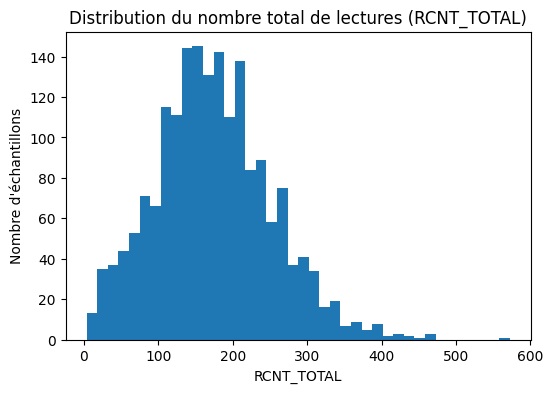

RCNT_TOTAL: min/median/mean/max = 4.0 172.0 174.73228772309358 572.0


In [ ]:
# --- dans le dataset agrégé (ds) : censure -120 et densité de lectures (RCNT)

rssi_cols = [c for c in ds.columns if c.startswith(("RMAX_","RMEAN_","RMIN_","RSTD_"))]
cnt_cols  = [c for c in ds.columns if c.startswith("RCNT_")]

# proportion de valeurs censurées (RSSI = -120) dans les features
censor_rate = (ds[rssi_cols] <= -119.9).mean().sort_values(ascending=False).head(15)
print("Top 15 variables les plus censurées (-120 dBm) :")
display(censor_rate.to_frame("censor_rate"))

# total de lectures par échantillon
ds["RCNT_TOTAL"] = ds[cnt_cols].sum(axis=1)

plt.figure(figsize=(6,4))
plt.hist(ds["RCNT_TOTAL"].to_numpy(float), bins=40)
plt.title("Distribution du nombre total de lectures (RCNT_TOTAL)")
plt.xlabel("RCNT_TOTAL")
plt.ylabel("Nombre d'échantillons")
plt.show()

print("RCNT_TOTAL: min/median/mean/max =",
      float(ds["RCNT_TOTAL"].min()),
      float(ds["RCNT_TOTAL"].median()),
      float(ds["RCNT_TOTAL"].mean()),
      float(ds["RCNT_TOTAL"].max()))

## 5) Géométrie : coordonnées des antennes et distances vraies

Le fichier `antConf=square2m.csv` donne les coordonnées $(x_j,y_j,z_j)$ des 4 antennes.

On calcule ensuite les distances vraies :
$$
D_j = \sqrt{(x-x_j)^2 + (y-y_j)^2 + (z-z_j)^2}
$$

Ces distances servent à deux choses :
- construire les variantes “physiques” (prédire \(D_1..D_4\)),
- analyser les limites géométriques (antennes coplanaires → estimation de z instable).

In [ ]:
ANTCONF = os.path.join(CONF_DIR, "antConf=square2m.csv")
ant = pd.read_csv(ANTCONF, sep=";").sort_values("Antenna")
coords = ant[["x","y","z"]].to_numpy(float)
display(ant)

def distances_from_xyz(xyz: np.ndarray, coords: np.ndarray) -> np.ndarray:
    diff = xyz[:, None, :] - coords[None, :, :]
    return np.sqrt((diff**2).sum(axis=2))

D_true = distances_from_xyz(Y_xyz, coords)  # (n,4)

,Antenna,x,y,z
0,1,1,1,0
1,2,-1,1,0
2,3,-1,-1,0
3,4,1,-1,0


## 6) Validation et KPI (évaluation fiable)

### 6.1 Pourquoi GroupKFold ?

Si on fait une validation “aléatoire”, on risque d'avoir la même position \((x,y)\) en train et en test.
Dans ce cas, le modèle peut simplement mémoriser le pattern RSSI d'un point de la grille, et l'évaluation devient trop optimiste.

On utilise donc `GroupKFold` avec un groupe par position \((x,y)\).  
Ainsi, une position donnée n'apparaît jamais à la fois en apprentissage et en test.

### 6.2 KPI utilisés

On suit principalement l'erreur 2D :
$$
e_{2D}=\sqrt{(\hat{x}-x)^2+(\hat{y}-y)^2}
$$
et l'erreur 3D :
$$
e_{3D}=\sqrt{(\hat{x}-x)^2+(\hat{y}-y)^2+(\hat{z}-z)^2}.
$$

On ajoute des quantiles (90\%, 95\%) et un taux d'outliers (>2 m) pour caractériser la queue de distribution.

In [ ]:
gkf = GroupKFold(n_splits=5)
groups = (ds["x"].astype(str) + "_" + ds["y"].astype(str)).to_numpy()

def kpis_from_pred(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    e2d = np.sqrt(((y_pred[:,:2]-y_true[:,:2])**2).sum(axis=1))
    e3d = np.sqrt(((y_pred-y_true)**2).sum(axis=1))
    return {
        "RMSE_xyz": rmse,
        "mean_2D": float(e2d.mean()),
        "mean_3D": float(e3d.mean()),
        "q90_2D": float(np.quantile(e2d, 0.90)),
        "q95_2D": float(np.quantile(e2d, 0.95)),
        "out_2D_gt2m_%": float((e2d>2.0).mean()*100.0),
    }

def eval_cv_xyz(model, X: pd.DataFrame, Y: np.ndarray, groups: np.ndarray) -> dict:
    rows = []
    for tr, te in gkf.split(X, Y, groups):
        model.fit(X.iloc[tr], Y[tr])
        pred = model.predict(X.iloc[te])
        rows.append(kpis_from_pred(Y[te], pred))
    return {k: float(v) for k,v in pd.DataFrame(rows).mean().to_dict().items()}

def oof_predict_xyz(model, X: pd.DataFrame, Y: np.ndarray, groups: np.ndarray) -> np.ndarray:
    oof = np.zeros_like(Y)
    for tr, te in gkf.split(X, Y, groups):
        model.fit(X.iloc[tr], Y[tr])
        oof[te] = model.predict(X.iloc[te])
    return oof

## 7) Étape 1 — Benchmark : baseline vs features enrichies

On commence par une comparaison structurée :
- plusieurs modèles standards (linéaire, voisins, arbres, boosting),
- plusieurs jeux de features (baseline RSSImax vs features enrichies).

**Objectif :** vérifier que les améliorations (features) apportent un gain mesurable sur les KPI.



In [ ]:
def make_models():
    return {
        "Ridge": Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=10.0, random_state=RANDOM_STATE))]),
        "kNN":   Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=25, weights="distance"))]),
        "RF":    RandomForestRegressor(n_estimators=600, random_state=RANDOM_STATE, n_jobs=-1),
        "ET":    ExtraTreesRegressor(n_estimators=800, random_state=RANDOM_STATE, n_jobs=-1),
        "HGB":   MultiOutputRegressor(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

feature_sets = {
    "Baseline_RSSImax_12": FEATURES_BASELINE,
    "Stats_full": FEATURES_STATS,
    "Stats_inv_diff": FEATURES_RICH,
}

rows = []
for fs_name, feats in feature_sets.items():
    X = ds[feats].copy()
    for mname, model in make_models().items():
        metrics = eval_cv_xyz(model, X, Y_xyz, groups)
        rows.append({"Model": mname, "Features": fs_name, **metrics})

leaderboard = pd.DataFrame(rows).sort_values(["mean_2D","mean_3D","RMSE_xyz"])
display(leaderboard)

,Model,Features,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
12,RF,Stats_inv_diff,0.927453,1.207117,1.450949,2.208487,2.730552,13.226646
13,ET,Stats_inv_diff,0.935164,1.215447,1.460540,2.222447,2.766026,13.599404
14,HGB,Stats_inv_diff,0.957225,1.234577,1.490122,2.261904,2.766001,15.170250
4,HGB,Baseline_RSSImax_12,0.964670,1.267239,1.518404,2.232206,2.661591,15.001662
9,HGB,Stats_full,0.986242,1.289287,1.543110,2.408874,2.820405,17.933322
2,RF,Baseline_RSSImax_12,0.976178,1.297445,1.543934,2.277241,2.790588,14.950367
10,Ridge,Stats_inv_diff,0.960097,1.300030,1.531390,2.214604,2.548485,16.302315
5,Ridge,Stats_full,0.967857,1.314439,1.546265,2.242512,2.553098,17.119081
1,kNN,Baseline_RSSImax_12,0.991885,1.323977,1.568006,2.327379,2.814259,17.390549
7,RF,Stats_full,0.991013,1.333697,1.563061,2.409289,2.868978,17.238069


## 7bis) Contrôle expérimental : ablation study (effet des features)

Un rendu solide doit montrer un **contrôle expérimental** : on modifie un seul élément à la fois,
et on mesure l'impact sur les KPI.

Ici, on fixe :
- le même modèle (RandomForest avec des hyperparamètres raisonnables),
- la même validation (GroupKFold par position),
et on compare plusieurs familles de variables :

1) baseline \(RMAX\) seulement,  
2) + statistiques (moyenne, std, min, RCNT),  
3) + résumés par antenne (AX\_*) et contrastes (DIF\_*),  
4) + ajout explicite de RCNT, puis sans RCNT (pour isoler sa contribution).

L'objectif est de répondre clairement à : *« qu'est-ce qui apporte quoi ? »*.

In [ ]:
from copy import deepcopy

def eval_feature_set(name, feats, model=None):
    if model is None:
        model = RandomForestRegressor(
            n_estimators=600, random_state=RANDOM_STATE, n_jobs=-1,
            max_features="sqrt", min_samples_leaf=1
        )
    X = ds[feats].copy()
    return {"FeatureSet": name, **eval_cv_xyz(model, X, Y_xyz, groups)}

# variantes de features pour l'ablation
feats_rmax = FEATURES_BASELINE

# stats (inclut RCNT)
feats_stats = FEATURES_STATS

# rich (stats + résumés + contrastes)
feats_rich = FEATURES_RICH

# rich sans RCNT (on retire toutes les colonnes RCNT_ et AX_CNT_A*)
feats_rich_no_rcnt = [c for c in feats_rich if not c.startswith("RCNT_") and not c.startswith("AX_CNT_")]

# stats sans RCNT
feats_stats_no_rcnt = [c for c in feats_stats if not c.startswith("RCNT_")]

rows = []
rows.append(eval_feature_set("Baseline: RMAX only", feats_rmax))
rows.append(eval_feature_set("Stats: RMAX/RMEAN/RSTD/RMIN/RCNT", feats_stats))
rows.append(eval_feature_set("Stats (no RCNT)", feats_stats_no_rcnt))
rows.append(eval_feature_set("Rich: Stats + AX_* + DIF_*", feats_rich))
rows.append(eval_feature_set("Rich (no RCNT)", feats_rich_no_rcnt))

ablation = pd.DataFrame(rows).sort_values(["mean_2D","mean_3D","RMSE_xyz"])
display(ablation)

,FeatureSet,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
3,Rich: Stats + AX_* + DIF_*,0.913714,1.198993,1.442183,2.128418,2.557305,12.633558
4,Rich (no RCNT),0.924550,1.212246,1.461376,2.137978,2.534993,12.736532
0,Baseline: RMAX only,0.952278,1.263476,1.510189,2.168441,2.646048,13.171381
2,Stats (no RCNT),0.958007,1.273516,1.519117,2.219206,2.613516,14.904959
1,Stats: RMAX/RMEAN/RSTD/RMIN/RCNT,0.955417,1.277484,1.512819,2.238940,2.664508,15.282807


## 8) Étape 2 — Tuning (optimisation) sur les meilleurs modèles

Après le benchmark, on optimise les modèles d'arbres (RF / ExtraTrees), car ils sont généralement performants sur ce type de problème non-linéaire.

On utilise `RandomizedSearchCV` avec `GroupKFold`, et on optimise directement l'erreur moyenne 2D (KPI principal).

Pour limiter le temps de calcul, on utilise :
- `n_iter = 10`,
- `n_estimators ∈ {200, 400, 700}`.

**Remarque :** même un tuning “léger” reste coûteux, car :
$$
n\_iter \times n\_folds \approx 10 \times 5 = 50\ \text{entraînements par modèle}.
$$

In [ ]:
TUNE_FEATURES = "Stats_inv_diff"
X_tune = ds[feature_sets[TUNE_FEATURES]].copy()

def mean_2d_error(y_true, y_pred):
    return np.sqrt(((y_pred[:,:2]-y_true[:,:2])**2).sum(axis=1)).mean()

scorer = make_scorer(mean_2d_error, greater_is_better=False)
cv = list(gkf.split(X_tune, Y_xyz, groups))

# RandomForest
rf_base = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
rf_space = {
    "n_estimators": [200, 400, 700],
    "max_depth": [None, 14, 22, 30],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.4, 0.6, 0.8],
}
rf_search = RandomizedSearchCV(rf_base, rf_space, n_iter=10, scoring=scorer, cv=cv,
                               random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
rf_search.fit(X_tune, Y_xyz)
rf_best = rf_search.best_estimator_
rf_metrics = eval_cv_xyz(rf_best, X_tune, Y_xyz, groups)

# ExtraTrees
et_base = ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1)
et_space = {
    "n_estimators": [200, 400, 700],
    "max_depth": [None, 14, 22, 30],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.4, 0.6, 0.8],
}
et_search = RandomizedSearchCV(et_base, et_space, n_iter=10, scoring=scorer, cv=cv,
                               random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
et_search.fit(X_tune, Y_xyz)
et_best = et_search.best_estimator_
et_metrics = eval_cv_xyz(et_best, X_tune, Y_xyz, groups)

print("Best RF params :", rf_search.best_params_)
print("RF tuned KPI   :", rf_metrics)
print("Best ET params :", et_search.best_params_)
print("ET tuned KPI   :", et_metrics)

tuned = pd.DataFrame([
    {"Model":"RF_tuned","Features":TUNE_FEATURES, **rf_metrics},
    {"Model":"ET_tuned","Features":TUNE_FEATURES, **et_metrics},
]).sort_values(["mean_2D","mean_3D","RMSE_xyz"])
display(tuned)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best RF params : {'n_estimators': 700, 'min_samples_leaf': 4, 'max_features': 0.6, 'max_depth': 14}
RF tuned KPI   : {'RMSE_xyz': 0.904170172463672, 'mean_2D': 1.180842542907833, 'mean_3D': 1.4248641777219402, 'q90_2D': 2.0828941306396644, 'q95_2D': 2.603570251475757, 'out_2D_gt2m_%': 12.139762920293643}
Best ET params : {'n_estimators': 700, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 30}
ET tuned KPI   : {'RMSE_xyz': 0.924364928792544, 'mean_2D': 1.207285525197231, 'mean_3D': 1.4505901308970506, 'q90_2D': 2.1973374577398253, 'q95_2D': 2.6566011354187804, 'out_2D_gt2m_%': 13.110450991684198}


,Model,Features,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
0,RF_tuned,Stats_inv_diff,0.904170,1.180843,1.424864,2.082894,2.603570,12.139763
1,ET_tuned,Stats_inv_diff,0.924365,1.207286,1.450590,2.197337,2.656601,13.110451


## 8bis) Traitement RTLS de $z$ : classification de hauteur puis régression $(x,y)$

Dans cette campagne, $z$ ne prend que **trois valeurs** : $0.5$, $1.5$ et $2.5$ m.  
Dans une configuration avec antennes **coplanaires**, l'information verticale est faible et bruitée :
prédire $z$ comme une variable continue peut être instable.

Une stratégie RTLS raisonnable est alors :

1) **classifier** la hauteur $\hat{z}\in\{0.5,1.5,2.5\}$,  
2) **régréssion** de $(x,y)$ conditionnée à la classe prédite.

On compare cette approche à la régression directe $(x,y,z)$.

Important : on implémente l'évaluation sans fuite de données, dans une boucle GroupKFold.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

Z_levels = np.array([0.5, 1.5, 2.5], float)

def z_to_class(z):
    # map exact -> classe 0/1/2 (robuste si z est float exact)
    return np.argmin(np.abs(z.reshape(-1,1) - Z_levels.reshape(1,-1)), axis=1)

def class_to_z(k):
    return Z_levels[k]

def eval_two_stage_zxy(X: pd.DataFrame, Y_xyz: np.ndarray, groups: np.ndarray,
                       clf=None, reg_xy=None) -> dict:
    if clf is None:
        clf = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
    if reg_xy is None:
        reg_xy = RandomForestRegressor(n_estimators=600, random_state=RANDOM_STATE, n_jobs=-1)

    rows = []
    for tr, te in gkf.split(X, Y_xyz, groups):
        Xtr, Xte = X.iloc[tr], X.iloc[te]
        Ytr, Yte = Y_xyz[tr], Y_xyz[te]

        ztr_cls = z_to_class(Ytr[:,2])

        # 1) classification de z
        clf.fit(Xtr, ztr_cls)
        zte_pred_cls = clf.predict(Xte)
        zte_pred = class_to_z(zte_pred_cls)

        # 2) régression de (x,y) conditionnée à la classe prédite
        # on entraîne un modèle par classe sur le train
        regs = {}
        for k in range(len(Z_levels)):
            mask_k = (ztr_cls == k)
            if mask_k.sum() < 10:
                regs[k] = deepcopy(reg_xy).fit(Xtr, Ytr[:, :2])  # fallback
            else:
                regs[k] = deepcopy(reg_xy).fit(Xtr[mask_k], Ytr[mask_k, :2])

        xy_pred = np.zeros((len(te),2), float)
        for k in range(len(Z_levels)):
            mk = (zte_pred_cls == k)
            if mk.any():
                xy_pred[mk] = regs[k].predict(Xte[mk])

        y_pred = np.column_stack([xy_pred, zte_pred])
        rows.append(kpis_from_pred(Yte, y_pred))

    return {k: float(v) for k,v in pd.DataFrame(rows).mean().to_dict().items()}

X_for_z = X_tune  # mêmes features que pour le tuning
kpi_two_stage = eval_two_stage_zxy(X_for_z, Y_xyz, groups)

compare_z = pd.DataFrame([
    {"Model":"RF tuned direct xyz", **rf_metrics},
    {"Model":"Two-stage: clf(z)+reg(xy|z)", **kpi_two_stage},
]).sort_values(["mean_2D","mean_3D","RMSE_xyz"])

display(compare_z)

,Model,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
0,RF tuned direct xyz,0.904170,1.180843,1.424864,2.082894,2.603570,12.139763
1,Two-stage: clf(z)+reg(xy|z),0.999478,1.239901,1.552550,2.271391,2.695515,14.589868


## 9) Variante A — Approche “physique” : RSSI → distances → trilatération

Le sujet propose une variante “plus physique” :
1. prédire les distances \(D_1..D_4\) aux antennes,
2. reconstruire \((x,y,z)\) par trilatération.

### 9.1 Attention : antennes coplanaires → z instable

Ici les antennes sont au plan \(z=0\).  
La trilatération est donc **mal conditionnée** pour l'axe vertical : plusieurs solutions peuvent expliquer des distances proches,
et une petite erreur sur \(D_j\) se traduit par une grande erreur sur \(z\).

Pour tenir compte du protocole (3 hauteurs seulement), on teste aussi une correction simple :
$$
\hat{z} \leftarrow \operatorname{argmin}_{z\in\{0.5,1.5,2.5\}} |\hat{z}-z|.
$$
C'est la variante `snapZ`.

In [ ]:
def trilaterate_planar(d: np.ndarray, coords: np.ndarray) -> np.ndarray:
    # Reconstruction (x,y) via différences d'équations de sphères, puis estimation de z
    x1, y1, z1 = coords[0]
    A, c = [], []
    for i in range(1, 4):
        xi, yi, zi = coords[i]
        A.append([2*(xi-x1), 2*(yi-y1)])
        c.append((xi**2-x1**2) + (yi**2-y1**2))
    A = np.array(A, float)
    c = np.array(c, float)
    Ap = np.linalg.pinv(A)

    d1 = d[:, 0:1]
    bi = (d1**2 - d[:, 1:]**2) + c[None, :]
    xy = bi @ Ap.T
    x, y = xy[:, 0], xy[:, 1]

    zs = []
    for j in range(4):
        xi, yi, zi = coords[j]
        zsq = d[:, j]**2 - (x-xi)**2 - (y-yi)**2
        zs.append(np.sqrt(np.clip(zsq, 0, None)) + zi)
    z = np.vstack(zs).mean(axis=0)
    return np.column_stack([x,y,z])

def snap_z(z_pred: np.ndarray, allowed=(0.5,1.5,2.5)) -> np.ndarray:
    allowed = np.array(allowed, float)
    idx = np.argmin(np.abs(z_pred[:,None] - allowed[None,:]), axis=1)
    return allowed[idx]

def eval_dist_trilat(model_dist, X: pd.DataFrame, D: np.ndarray, Y: np.ndarray, groups: np.ndarray, do_snap=False) -> dict:
    rows = []
    for tr, te in gkf.split(X, Y, groups):
        model_dist.fit(X.iloc[tr], D[tr])
        d_pred = model_dist.predict(X.iloc[te])

        xyz_pred = trilaterate_planar(d_pred, coords)
        if do_snap:
            xyz_pred[:,2] = snap_z(xyz_pred[:,2])

        rows.append(kpis_from_pred(Y[te], xyz_pred))
    return {k: float(v) for k,v in pd.DataFrame(rows).mean().to_dict().items()}

# Modèle distance : forêt (robuste)
rf_dist = RandomForestRegressor(n_estimators=700, random_state=RANDOM_STATE, n_jobs=-1)

metrics_dist = eval_dist_trilat(rf_dist, X_tune, D_true, Y_xyz, groups, do_snap=False)
metrics_dist_snap = eval_dist_trilat(rf_dist, X_tune, D_true, Y_xyz, groups, do_snap=True)

variants_dist = pd.DataFrame([
    {"Model":"RF_dist_trilat","Features":TUNE_FEATURES, **metrics_dist},
    {"Model":"RF_dist_trilat_snapZ","Features":TUNE_FEATURES, **metrics_dist_snap},
]).sort_values(["mean_2D","mean_3D","RMSE_xyz"])
display(variants_dist)

,Model,Features,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
0,RF_dist_trilat,Stats_inv_diff,0.989649,1.194372,1.559119,2.202436,2.688227,13.05543
1,RF_dist_trilat_snapZ,Stats_inv_diff,1.012544,1.194372,1.592280,2.202436,2.688227,13.05543


## 10) Variante B — Prédire \((x,y,z,D_1..D_4)\) ensemble

Une autre idée proposée est de prédire plusieurs sorties simultanément :
\[
(x,y,z,D_1,D_2,D_3,D_4).
\]

Intuition : le modèle peut exploiter des relations internes entre les coordonnées et les distances.
Dans cette section, on entraîne un modèle multi-sortie sur 7 dimensions,
mais on évalue seulement la partie \((x,y,z)\) (KPI de localisation).

In [ ]:
Y_xyzD = np.column_stack([Y_xyz, D_true])

rf_xyzD = RandomForestRegressor(n_estimators=700, random_state=RANDOM_STATE, n_jobs=-1)

rows = []
for tr, te in gkf.split(X_tune, Y_xyzD, groups):
    rf_xyzD.fit(X_tune.iloc[tr], Y_xyzD[tr])
    pred7 = rf_xyzD.predict(X_tune.iloc[te])
    rows.append(kpis_from_pred(Y_xyz[te], pred7[:, :3]))

metrics_xyzD = {k: float(v) for k,v in pd.DataFrame(rows).mean().to_dict().items()}

variants_joint = pd.DataFrame([
    {"Model":"RF_joint_xyzD","Features":TUNE_FEATURES, **metrics_xyzD},
]).sort_values(["mean_2D","mean_3D","RMSE_xyz"])
display(variants_joint)

,Model,Features,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
0,RF_joint_xyzD,Stats_inv_diff,0.922549,1.195045,1.441575,2.179611,2.701798,13.111326


## 11) Variante C — Multi-puissance : modèles séparés puis fusion (late fusion)

Le sujet insiste sur l'utilisation des 3 puissances.  
Une stratégie simple et robuste consiste à :
1. entraîner un modèle par puissance (features issues uniquement de cette puissance),
2. combiner les prédictions.

On teste deux fusions :
- moyenne simple,
- moyenne pondérée (poids inverse de l'erreur 2D par puissance).



In [ ]:
POWERS = [24,27,30]

def power_feature_cols(power=24):
    cols = []
    for pr in ["RMAX","RMEAN","RSTD","RMIN","RCNT"]:
        cols += [c for c in ds.columns if c.startswith(f"{pr}_{power}_A")]
    return cols

def eval_power_models_fusion(base_model, fusion="mean"):
    # OOF par puissance
    per_power = {}
    preds = []
    for p in POWERS:
        feats_p = power_feature_cols(power=p)
        Xp = ds[feats_p].copy()
        oof = oof_predict_xyz(base_model, Xp, Y_xyz, groups)
        per_power[p] = kpis_from_pred(Y_xyz, oof)
        preds.append(oof)

    stack = np.stack(preds, axis=0)  # (3,n,3)

    if fusion == "mean":
        fused = stack.mean(axis=0)
    elif fusion == "weighted":
        w = np.array([1.0 / max(per_power[p]["mean_2D"], 1e-6) for p in POWERS], float)
        w = w / w.sum()
        fused = (stack * w[:,None,None]).sum(axis=0)
    else:
        raise ValueError("fusion doit être 'mean' ou 'weighted'")

    fused_kpi = kpis_from_pred(Y_xyz, fused)
    return per_power, fused_kpi

base_rf = RandomForestRegressor(n_estimators=600, random_state=RANDOM_STATE, n_jobs=-1)

per_power, kpi_mean = eval_power_models_fusion(base_rf, fusion="mean")
_, kpi_weighted = eval_power_models_fusion(base_rf, fusion="weighted")

tab_pp = pd.DataFrame([{"Power":p, **per_power[p]} for p in POWERS]).sort_values("Power")
display(tab_pp)

variants_fusion = pd.DataFrame([
    {"Model":"RF_power_fusion_mean","Features":"Stats_full_by_power", **kpi_mean},
    {"Model":"RF_power_fusion_weighted","Features":"Stats_full_by_power", **kpi_weighted},
]).sort_values(["mean_2D","mean_3D","RMSE_xyz"])
display(variants_fusion)

,Power,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
0,24,1.208707,1.710342,1.937627,2.922498,3.320670,36.668469
1,27,1.159755,1.623503,1.839452,2.995201,3.346244,27.528394
2,30,1.120119,1.543189,1.769316,2.745862,3.320947,25.473229


,Model,Features,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
1,RF_power_fusion_weighted,Stats_full_by_power,1.037687,1.452027,1.670019,2.485233,2.799997,22.228231
0,RF_power_fusion_mean,Stats_full_by_power,1.039233,1.454964,1.672904,2.489363,2.797406,22.390481


## 11bis) Multi-puissance : fusion apprise (stacking)

La fusion par moyenne (ou moyenne pondérée) est simple mais limitée : elle ne peut pas apprendre
que certaines puissances sont plus fiables dans certaines zones.

On met en place une **fusion apprise** (stacking) :

- Niveau 1 : trois modèles (un par puissance) prédisent $(x,y,z)$.
- Niveau 2 : un modèle \emph{meta} apprend à combiner ces trois prédictions.

Pour éviter toute fuite de données, on évalue le stacking via une boucle \textbf{externe} GroupKFold.
Dans chaque fold externe :
1) on génère des prédictions OOF (niveau 1) sur le train via une CV interne,
2) on entraîne le meta-modèle sur ces prédictions OOF,
3) on prédit sur le test du fold externe.

C'est plus coûteux, mais c'est exactement le type de rigueur attendu sur un projet complet.

In [ ]:
from sklearn.base import clone

def stacking_fusion_xyz(
    base_model,
    meta_model,
    ds: pd.DataFrame,
    Y_xyz: np.ndarray,
    groups: np.ndarray,
    powers=(24,27,30),
    n_inner_splits=4
) -> dict:
    # CV externe = évaluation
    outer = GroupKFold(n_splits=5)
    rows = []

    for tr_out, te_out in outer.split(ds, Y_xyz, groups):
        ds_tr = ds.iloc[tr_out].reset_index(drop=True)
        ds_te = ds.iloc[te_out].reset_index(drop=True)
        y_tr = Y_xyz[tr_out]
        y_te = Y_xyz[te_out]
        g_tr = groups[tr_out]

        # CV interne pour produire OOF base preds sur train
        n_groups = len(np.unique(g_tr))
        inner_splits = min(n_inner_splits, n_groups) if n_groups >= 2 else 2
        inner = GroupKFold(n_splits=inner_splits)

        oof_lvl1 = np.zeros((len(ds_tr), len(powers)*3), float)

        for p_idx, p in enumerate(powers):
            feats_p = power_feature_cols(power=p)
            Xp_tr = ds_tr[feats_p]
            # OOF interne
            oof_p = np.zeros((len(ds_tr), 3), float)
            for tr_in, te_in in inner.split(Xp_tr, y_tr, g_tr):
                m = clone(base_model)
                m.fit(Xp_tr.iloc[tr_in], y_tr[tr_in])
                oof_p[te_in] = m.predict(Xp_tr.iloc[te_in])
            oof_lvl1[:, p_idx*3:(p_idx+1)*3] = oof_p

        # entraînement meta sur train
        meta = clone(meta_model)
        meta.fit(oof_lvl1, y_tr)

        # prédictions niveau 1 sur test (base entraînés sur tout train)
        lvl1_test = np.zeros((len(ds_te), len(powers)*3), float)
        for p_idx, p in enumerate(powers):
            feats_p = power_feature_cols(power=p)
            Xp_tr = ds_tr[feats_p]
            Xp_te = ds_te[feats_p]
            m = clone(base_model)
            m.fit(Xp_tr, y_tr)
            lvl1_test[:, p_idx*3:(p_idx+1)*3] = m.predict(Xp_te)

        y_pred = meta.predict(lvl1_test)
        rows.append(kpis_from_pred(y_te, y_pred))

    return {k: float(v) for k,v in pd.DataFrame(rows).mean().to_dict().items()}

base_lvl1 = RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1, max_features="sqrt")
meta = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=1.0, random_state=RANDOM_STATE))])

kpi_stacking = stacking_fusion_xyz(base_lvl1, meta, ds, Y_xyz, groups, powers=(24,27,30), n_inner_splits=4)

variants_stack = pd.DataFrame([
    {"Model":"Fusion mean (late)", **kpi_mean},
    {"Model":"Fusion weighted (late)", **kpi_weighted},
    {"Model":"Stacking (learned fusion)", **kpi_stacking},
]).sort_values(["mean_2D","mean_3D","RMSE_xyz"])
display(variants_stack)

,Model,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
2,Stacking (learned fusion),1.023010,1.413809,1.638918,2.410801,2.663741,21.771400
1,Fusion weighted (late),1.037687,1.452027,1.670019,2.485233,2.799997,22.228231
0,Fusion mean (late),1.039233,1.454964,1.672904,2.489363,2.797406,22.390481


## 12) RTLS engineering 1 — Calibration simple par puissance (recentrage)

Même si les forêts supportent des offsets, un traitement “ingénierie” consiste à réduire les biais systématiques.

Ici on teste un recentrage simple :
$$
R'_{p,a} = R_{p,a} - \mu_{p,a},
$$
où $\mu_{p,a}$ est la moyenne globale observée pour la puissance \(p\) et l'antenne \(a\).

C'est une calibration légère mais utile pour tester si les décalages de puissance perturbent l'apprentissage.

In [ ]:
def calibrate_by_power_antenna(df: pd.DataFrame, prefixes=("RMAX","RMEAN","RMIN")) -> pd.DataFrame:
    Xc = df.copy()
    for pr in prefixes:
        for p in [24,27,30]:
            for a in [1,2,3,4]:
                col = f"{pr}_{p}_A{a}"
                if col in Xc.columns:
                    Xc[col] = Xc[col] - float(Xc[col].mean())
    return Xc

X_uncal = ds[FEATURES_RICH].copy()
X_cal = calibrate_by_power_antenna(X_uncal)

rf_ref = RandomForestRegressor(n_estimators=600, random_state=RANDOM_STATE, n_jobs=-1)

kpi_uncal = eval_cv_xyz(rf_ref, X_uncal, Y_xyz, groups)
kpi_cal   = eval_cv_xyz(rf_ref, X_cal,   Y_xyz, groups)

variants_cal = pd.DataFrame([
    {"Model":"RF_uncalibrated","Features":"Stats_inv_diff", **kpi_uncal},
    {"Model":"RF_calibrated","Features":"Stats_inv_diff_cal", **kpi_cal},
]).sort_values(["mean_2D","mean_3D","RMSE_xyz"])
display(variants_cal)

,Model,Features,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
1,RF_calibrated,Stats_inv_diff_cal,0.927436,1.207091,1.450932,2.208019,2.731204,13.280555
0,RF_uncalibrated,Stats_inv_diff,0.927453,1.207117,1.450949,2.208487,2.730552,13.226646


## 13) RTLS engineering 2 — Modèle physique RSSI → distance (log-distance)

On teste un modèle de propagation très simple, souvent utilisé comme première approximation :
$$
RSSI \approx A - 10n\log_{10}(d).
$$

En environnement indoor, ce modèle est imparfait (multi-trajets, masquage, orientation).
Mais il est intéressant pour :
- avoir une baseline “physique” interprétable,
- comprendre pourquoi la relation RSSI-distance n'est pas parfaitement monotone.

On calibre \((A,n)\) par régression linéaire, séparément pour chaque couple (puissance, antenne),
puis on convertit RSSI en distance estimée, et on trilatère.  
On applique ensuite `snapZ` car \(z\) est instable avec antennes coplanaires.

In [ ]:
# --- 1) Calibration log-distance robuste (on ignore les non-détections)
def fit_log_distance_models(
    ds: pd.DataFrame,
    D_true: np.ndarray,
    rssi_floor: float = -110.0,   # seuil : en dessous, on considère "non-détection / trop bruité"
    d_min: float = 0.2,
    d_max: float = 10.0
) -> dict:
    """
    Calibre, pour chaque (power, antenna), un modèle:
        RSSI ≈ A - 10 n log10(d)

    Robustesse:
    - on ignore les RSSI trop faibles (ex: -120),
    - on ignore les distances hors plage,
    - si trop peu de points valides -> on ne crée pas de modèle.
    """
    models = {}

    for p in [24, 27, 30]:
        for a in [1, 2, 3, 4]:
            col = f"RMAX_{p}_A{a}"
            if col not in ds.columns:
                continue

            rssi = ds[col].to_numpy(float)
            d = D_true[:, a - 1].astype(float)

            # masque "données plausibles"
            m = np.isfinite(rssi) & np.isfinite(d)
            m &= (rssi > rssi_floor)
            m &= (d >= d_min) & (d <= d_max)

            if m.sum() < 30:
                # pas assez de points fiables -> on skip
                continue

            x = np.log10(np.clip(d[m], 1e-3, None)).reshape(-1, 1)
            y = rssi[m].reshape(-1, 1)

            lr = LinearRegression()
            lr.fit(x, y)

            A = float(lr.intercept_[0])
            b1 = float(lr.coef_[0, 0])     # ~ -10n
            n = -b1 / 10.0

            # sécurité : éviter n nul/négatif (sinon distances explosent)
            if not np.isfinite(n) or n <= 0:
                continue

            models[(p, a)] = (A, n)

    return models


# --- 2) Conversion RSSI -> distance avec clipping pour éviter overflow
def rssi_to_dist(
    rssi: np.ndarray,
    A: float,
    n: float,
    exp_clip: float = 3.0,   # 10^3 = 1000 -> limite haute (évite overflow)
    d_min: float = 0.2,
    d_max: float = 10.0
) -> np.ndarray:
    """
    RSSI = A - 10n log10(d)  => d = 10^((A - RSSI)/(10n))

    Robustesse:
    - clip de l'exposant pour éviter overflow
    - clip des distances dans [d_min, d_max]
    """
    n = max(float(n), 1e-6)

    exp = (A - rssi) / (10.0 * n)
    exp = np.clip(exp, -exp_clip, exp_clip)   # évite 10**(très grand)
    d = 10.0 ** exp

    # nettoyage
    d = np.where(np.isfinite(d), d, d_max)
    d = np.clip(d, d_min, d_max)
    return d


# --- 3) Estimation des distances : moyenne sur puissances disponibles + fallback
def estimate_distances_from_rssi(
    ds: pd.DataFrame,
    logdist: dict,
    rssi_floor: float = -110.0,
    d_min: float = 0.2,
    d_max: float = 10.0
) -> np.ndarray:
    """
    Produit D_est (n,4). Pour chaque antenne:
    - on calcule une distance estimée pour chaque puissance disposant d'un modèle
    - on moyenne ces estimations
    - si rien de valide : fallback = d_max
    """
    n_samples = ds.shape[0]
    D_est = np.full((n_samples, 4), d_max, float)

    for a in [1, 2, 3, 4]:
        est_list = []

        for p in [24, 27, 30]:
            key = (p, a)
            col = f"RMAX_{p}_A{a}"
            if key not in logdist or col not in ds.columns:
                continue

            A, nn = logdist[key]
            rssi = ds[col].to_numpy(float)

            # on ignore les non-détections (elles faussent énormément)
            rssi_use = rssi.copy()
            rssi_use = np.where(rssi_use > rssi_floor, rssi_use, np.nan)

            d_hat = rssi_to_dist(rssi_use, A, nn, d_min=d_min, d_max=d_max)
            est_list.append(d_hat)

        if len(est_list) > 0:
            # moyenne robuste: nanmean
            d_a = np.nanmean(np.vstack(est_list), axis=0)
            d_a = np.where(np.isfinite(d_a), d_a, d_max)
            d_a = np.clip(d_a, d_min, d_max)
            D_est[:, a - 1] = d_a

    return D_est


# --- 4) Exécution robuste de toute la variante physique
logdist = fit_log_distance_models(ds, D_true, rssi_floor=-110.0, d_min=0.2, d_max=10.0)
print("Nb modèles (power,antenna) calibrés :", len(logdist))

D_est = estimate_distances_from_rssi(ds, logdist, rssi_floor=-110.0, d_min=0.2, d_max=10.0)

# Si jamais D_est contient encore des NaN (très rare), on sécurise
D_est = np.nan_to_num(D_est, nan=10.0, posinf=10.0, neginf=10.0)

xyz_phys = trilaterate_planar(D_est, coords)

# sécurité post-trilatération
xyz_phys = np.nan_to_num(xyz_phys, nan=0.0, posinf=0.0, neginf=0.0)

# snap Z vers les niveaux autorisés
xyz_phys[:, 2] = snap_z(xyz_phys[:, 2])

kpi_phys = kpis_from_pred(Y_xyz, xyz_phys)

variants_phys = pd.DataFrame([
    {"Model": "LogDist_trilat_snapZ", "Features": "RMAX only + physics (robust)", **kpi_phys},
]).sort_values(["mean_2D", "mean_3D", "RMSE_xyz"])

display(variants_phys)


Nb modèles (power,antenna) calibrés : 9


,Model,Features,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
0,LogDist_trilat_snapZ,RMAX only + physics (robust),8.223552,12.314655,12.451995,21.759877,23.436525,95.294754


## 14) Restreindre le domaine : inside 2×2 vs outside

Le sujet mentionne que les performances peuvent être meilleures si l'on se limite au carré des antennes.

On définit :
- **inside** : $|x|\le 1$ et $|y|\le 1$  (carré 2×2 m),
- **outside** : toutes les autres positions.

On évalue les KPI séparément pour comparer les deux régimes.

**Intérêt :** on ne mélange pas des conditions physiques différentes (géométrie favorable au centre vs dégradation aux bords).

In [ ]:
inside = (ds["x"].abs() <= 1.0) & (ds["y"].abs() <= 1.0)
outside = ~inside

def eval_subset(model, X: pd.DataFrame, Y: np.ndarray, groups: np.ndarray, mask: np.ndarray) -> dict:
    Xs = X.loc[mask].reset_index(drop=True)
    Ys = Y[mask]
    gs = groups[mask]
    n_groups = len(np.unique(gs))
    n_splits = min(5, n_groups) if n_groups >= 2 else 2
    gkf_local = GroupKFold(n_splits=n_splits)

    rows = []
    for tr, te in gkf_local.split(Xs, Ys, gs):
        model.fit(Xs.iloc[tr], Ys[tr])
        pred = model.predict(Xs.iloc[te])
        rows.append(kpis_from_pred(Ys[te], pred))
    return {k: float(v) for k,v in pd.DataFrame(rows).mean().to_dict().items()}

best_direct = rf_best
Xbest = X_tune

kpi_all = eval_cv_xyz(best_direct, Xbest, Y_xyz, groups)
kpi_in  = eval_subset(best_direct, Xbest, Y_xyz, groups, inside.to_numpy())
kpi_out = eval_subset(best_direct, Xbest, Y_xyz, groups, outside.to_numpy())

tab_zone = pd.DataFrame([
    {"Zone":"ALL", **kpi_all},
    {"Zone":"INSIDE (2x2)", **kpi_in},
    {"Zone":"OUTSIDE", **kpi_out},
])
display(tab_zone)

,Zone,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
0,ALL,0.904170,1.180843,1.424864,2.082894,2.603570,12.139763
1,INSIDE (2x2),0.713555,0.915204,1.197973,1.231309,1.328437,0.000000
2,OUTSIDE,1.002465,1.379650,1.603240,2.347940,2.687364,17.545196


## 15) Analyse d'erreurs : zone, hauteur z, densité de lectures (RCNT)

Une moyenne globale peut masquer des comportements différents :
- le modèle peut être bon au centre et mauvais aux bords,
- le modèle peut estimer mieux certaines hauteurs,
- le modèle peut échouer quand il y a peu de lectures (signal intermittent).

On calcule donc des prédictions out-of-fold (OOF) sur le meilleur modèle direct,
puis on décompose l'erreur :

- par zone (inside/outside),
- par hauteur \(z\),
- par quantiles de `rcnt_total` (nombre total de lectures sur l'échantillon).


In [ ]:
oof_xyz = oof_predict_xyz(best_direct, Xbest, Y_xyz, groups)

e2d = np.sqrt(((oof_xyz[:,:2]-Y_xyz[:,:2])**2).sum(axis=1))
e3d = np.sqrt(((oof_xyz-Y_xyz)**2).sum(axis=1))

df_err = ds[["x","y","z"]].copy()
df_err["inside"] = inside.values
df_err["e2d"] = e2d
df_err["e3d"] = e3d

rcnt_cols = [c for c in ds.columns if c.startswith("RCNT_")]
df_err["rcnt_total"] = ds[rcnt_cols].sum(axis=1).to_numpy(float)
df_err["rcnt_bin"] = pd.qcut(df_err["rcnt_total"], q=4, duplicates="drop")

print("Erreur 2D globale : mean =", df_err["e2d"].mean(),
      "| median =", df_err["e2d"].median(),
      "| q90 =", df_err["e2d"].quantile(0.90),
      "| q95 =", df_err["e2d"].quantile(0.95),
      "| out>2m =", (df_err["e2d"]>2.0).mean()*100, "%")

# Résultats par zone / z / rcnt
display(df_err.groupby("inside")[["e2d","e3d"]].agg(["mean","median","count"]))
display(df_err.groupby("z")[["e2d","e3d"]].agg(["mean","median","count"]).sort_index())
display(df_err.groupby("rcnt_bin")[["e2d","e3d","rcnt_total"]].agg(["mean","median","count"]))

Erreur 2D globale : mean = 1.178518836152249 | median = 1.021797213950039 | q90 = 2.1582720626774523 | q95 = 2.623204251235404 | out>2m = 12.060573282855598 %


e2d                       e3d                
            mean    median count      mean    median count
inside                                                    
False   1.442822  1.240408  1174  1.649512  1.491904  1174
True    0.718827  0.673130   675  1.028829  0.998329   675

e2d                       e3d                
         mean    median count      mean    median count
z                                                      
0.5  1.086904  0.964962   608  1.490952  1.354990   608
1.5  1.170450  0.958567   618  1.221839  1.045533   618
2.5  1.275932  1.117028   623  1.556007  1.429969   623

/tmp/ipython-input-2229601651.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df_err.groupby("rcnt_bin")[["e2d","e3d","rcnt_total"]].agg(["mean","median","count"]))


e2d                       e3d                  \
                     mean    median count      mean    median count   
rcnt_bin                                                              
(7.999, 240.0]   1.506885  1.302703   479  1.744810  1.527353   479   
(240.0, 344.0]   1.056935  0.934922   486  1.329609  1.227448   486   
(344.0, 448.0]   1.027799  0.912672   444  1.296339  1.224989   444   
(448.0, 1144.0]  1.107432  0.993516   440  1.303316  1.231902   440   

                 rcnt_total               
                       mean median count  
rcnt_bin                                  
(7.999, 240.0]   162.538622  168.0   479  
(240.0, 344.0]   298.913580  304.0   486  
(344.0, 448.0]   397.837838  400.0   444  
(448.0, 1144.0]  559.981818  536.0   440

## 16) Visualisation RTLS : heatmap des erreurs sur la grille (x,y)

Pour un système de localisation sur grille, une visualisation essentielle est la carte d'erreur par position.

On agrège l'erreur 2D moyenne par \((x,y)\) et on affiche une heatmap (5×5).  
Cela permet d'identifier immédiatement :
- des zones où les antennes voient mal le tag (angles morts),
- des zones où la géométrie est défavorable (bords),
- des comportements anormaux (multi-trajets).

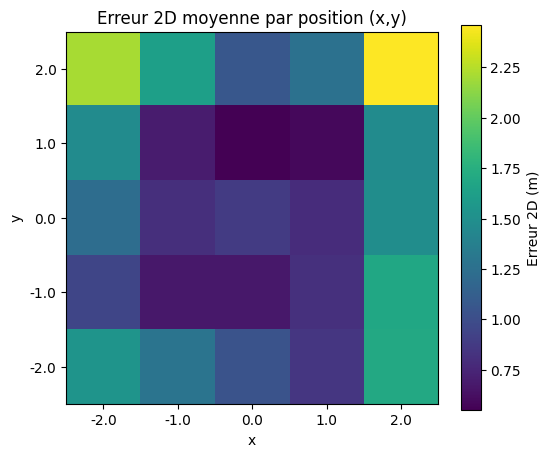

In [ ]:
grid = df_err.groupby(["x","y"])["e2d"].mean().reset_index()

xs = sorted(grid["x"].unique())
ys = sorted(grid["y"].unique(), reverse=True)

mat = np.full((len(ys), len(xs)), np.nan)
for _, r in grid.iterrows():
    mat[ys.index(r["y"]), xs.index(r["x"])] = r["e2d"]

plt.figure(figsize=(6,5))
im = plt.imshow(mat, aspect="equal")
plt.xticks(range(len(xs)), xs)
plt.yticks(range(len(ys)), ys)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Erreur 2D moyenne par position (x,y)")
plt.colorbar(im, label="Erreur 2D (m)")
plt.show()

## 17) Synthèse des variantes (tableau unique)

Pour conclure de manière claire, on rassemble toutes les approches dans un tableau comparatif :

- modèle direct optimisé (RF / ET),
- distances + trilatération (avec et sans snapZ),
- joint xyz + distances,
- fusion multi-puissance,
- calibration (recentrage),
- baseline physique log-distance.

Ce tableau est celui qui sert directement pour la discussion finale : ce qui marche, ce qui ne marche pas, et pourquoi.

In [ ]:
all_results = []

def add_result(name, feats, metrics):
    all_results.append({"Approche": name, "Features": feats, **metrics})

add_result("Direct RF tuned", TUNE_FEATURES, rf_metrics)
add_result("Direct ET tuned", TUNE_FEATURES, et_metrics)
add_result("Distances -> trilat", TUNE_FEATURES, metrics_dist)
add_result("Distances -> trilat + snapZ", TUNE_FEATURES, metrics_dist_snap)
add_result("Joint xyz + D1..D4", TUNE_FEATURES, metrics_xyzD)
add_result("Power fusion mean", "Stats_full_by_power", kpi_mean)
add_result("Power fusion weighted", "Stats_full_by_power", kpi_weighted)
add_result("RF calibrated", "Stats_inv_diff_cal", kpi_cal)
add_result("Physics log-distance", "RMAX + physics", kpi_phys)

summary = pd.DataFrame(all_results).sort_values(["mean_2D","mean_3D","RMSE_xyz"])
display(summary)

,Approche,Features,RMSE_xyz,mean_2D,mean_3D,q90_2D,q95_2D,out_2D_gt2m_%
0,Direct RF tuned,Stats_inv_diff,0.904170,1.180843,1.424864,2.082894,2.603570,12.139763
2,Distances -> trilat,Stats_inv_diff,0.989649,1.194372,1.559119,2.202436,2.688227,13.055430
3,Distances -> trilat + snapZ,Stats_inv_diff,1.012544,1.194372,1.592280,2.202436,2.688227,13.055430
4,Joint xyz + D1..D4,Stats_inv_diff,0.922549,1.195045,1.441575,2.179611,2.701798,13.111326
7,RF calibrated,Stats_inv_diff_cal,0.927436,1.207091,1.450932,2.208019,2.731204,13.280555
1,Direct ET tuned,Stats_inv_diff,0.924365,1.207286,1.450590,2.197337,2.656601,13.110451
6,Power fusion weighted,Stats_full_by_power,1.037687,1.452027,1.670019,2.485233,2.799997,22.228231
5,Power fusion mean,Stats_full_by_power,1.039233,1.454964,1.672904,2.489363,2.797406,22.390481
8,Physics log-distance,RMAX + physics,8.223552,12.314655,12.451995,21.759877,23.436525,95.294754


## 18) Conclusion (interprétation et limites)

À ce stade, le notebook permet de répondre aux attentes du sujet :

- la baseline est reproduite et dépassée par des features enrichies,
- plusieurs stratégies de modélisation sont comparées,
- une analyse d'erreurs (zone / z / RCNT / heatmap) est fournie,
- une discussion “RTLS engineering” est amorcée (calibration, physique, coplanarité).

Les limites principales sont structurelles :
- en indoor, la relation RSSI-distance est fortement bruitée (multi-trajets),
- l'estimation de z est difficile avec antennes coplanaires,
- la précision dépend fortement de la zone (centre vs bords) et du nombre de lectures.